# Smart Pantry: does the depletion model actually work?

A backtest of the app's prediction engine (`src/engine.py`) on **simulated households**.
Real beta data will replace the simulation later; the evaluation code stays the same.

**Setup.** Every household has its own true consumption rate for every item. We replay a year
of shopping. At each purchase, each model sees only the history logged so far, the way the app does,
and predicts, day by day, the chance the item is already used up.

**Models compared**
| Model | What it knows |
|---|---|
| Fixed 7 days | One curve for everything (median 7 days) |
| Category prior | The app on day one: per-category defaults, no learning |
| Item average only | Learns from this item's own history, no shrinkage |
| **Smart Pantry (app)** | The real engine: item → household category → population prior |
| Oracle | The true simulated parameters (upper bound, unreachable in practice) |

Run as a script (`python notebooks/evaluate_model.py`) or cell by cell in VS Code / Jupyter.

In [1]:
import math
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path(__file__).resolve().parents[1] if "__file__" in globals() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from engine import PantryDepletionEngine, mean_to_scale, median_to_scale  # noqa: E402
from config import RESTOCK_THRESHOLD  # noqa: E402

FIG_DIR = ROOT / "notebooks" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
engine = PantryDepletionEngine()

SEED = 42
N_HOUSEHOLDS = 200
DAYS = 365
REPORT_RAN_OUT = 0.6     # share of run-outs the user actually taps "Ran out" for
CONFIRM_ON_ALERT = 0.5   # chance the user taps "Still have it" when alerted and it's still there
TWO_PACK = 0.2           # chance a purchase is 2 packages instead of 1

## 1. Simulate households
The true per-item median is the category prior × a household factor (family size, habits)
× an item factor (this household loves bananas) × a category-level "the prior is off" factor.
The true shape ρ also differs from the model's, so the model is **not** given the right answer.

In [2]:
CATALOG = {
    "Dairy & Eggs": ["Milk", "Eggs", "Cottage cheese", "Yogurt", "Yellow cheese"],
    "Bakery & Bread": ["Bread", "Pita"],
    "Produce": ["Tomatoes", "Cucumbers", "Bananas", "Apples", "Onions"],
    "Meat & Poultry": ["Chicken breast", "Ground beef"],
    "Pantry Staples": ["Rice", "Pasta", "Olive oil", "Hummus"],
    "Frozen Foods": ["Frozen peas", "Schnitzel"],
    "Beverages": ["Coffee", "Orange juice"],
    "Snacks": ["Bamba", "Crackers"],
    "Cleaning": ["Dish soap", "Laundry detergent", "Toilet paper"],
}


def simulate(seed=SEED):
    rng = np.random.default_rng(seed)
    prior_error = {c: rng.lognormal(0, 0.2) for c in CATALOG}  # priors are educated guesses
    households = []
    for h in range(N_HOUSEHOLDS):
        hh_factor = rng.lognormal(0, 0.35)
        cats = list(CATALOG)
        items = []
        for c in rng.choice(cats, size=rng.integers(6, 10), replace=False):
            for name in rng.choice(CATALOG[c], size=min(len(CATALOG[c]), rng.integers(1, 3)), replace=False):
                p = engine.category_params(c)
                med = p["median_days"] * prior_error[c] * hh_factor * rng.lognormal(0, 0.35)
                rho = p["rho"] * rng.uniform(0.9, 1.6)
                items.append({"hh": h, "item": f"{h}:{name}", "name": name, "category": c,
                              "true_median": med, "true_rho": rho,
                              "true_scale": median_to_scale(med, rho)})
        households.append(items)
    return households, rng

## 2. Models
Every model turns the history logged *before* a purchase into a per-unit Weibull scale and a shape.
"Smart Pantry (app)" calls the real engine, the same function `pantry_service` uses at purchase time.

In [3]:
FIXED_RHO = 1.3
FIXED_SCALE = median_to_scale(7.0, FIXED_RHO)


def model_params(model, it, item_hist, cat_hist):
    """→ (per-unit scale, rho). item_hist / cat_hist are lists of per-unit intervals (days)."""
    c = it["category"]
    if model == "Fixed 7 days":
        return FIXED_SCALE, FIXED_RHO
    if model == "Category prior":
        return engine.prior_scale(c), engine.rho(c)
    if model == "Item average only":
        rho = engine.rho(c)
        if item_hist:
            return mean_to_scale(np.mean(item_hist), rho), rho
        return engine.prior_scale(c), rho
    if model == "Smart Pantry (app)":
        return engine.estimate_item_scale(c, item_hist, cat_hist), engine.rho(c)
    if model == "Oracle":
        return it["true_scale"], it["true_rho"]
    raise ValueError(model)


MODELS = ["Fixed 7 days", "Category prior", "Item average only", "Smart Pantry (app)", "Oracle"]


def p_gone(t, scale, rho, units, confirmed=None):
    """Vectorised copy of engine.depletion_probability (checked against it below)."""
    s = scale * max(0.05, units)
    st = np.exp(-(np.maximum(t, 0) / s) ** rho)
    if confirmed is None:
        return 1 - st
    c = np.minimum(confirmed, t)
    sc = np.exp(-(c / s) ** rho)
    out = np.where(c > 0, 1 - st / np.maximum(sc, 1e-12), 1 - st)
    return np.clip(out, 0, 1)


# The vectorised version must match the app's engine exactly.
for t, sc_, u, cf in [(3, 9.0, 1, None), (12, 5.5, 2, None), (10, 7.0, 1, 6), (30, 20.0, 0.5, 12)]:
    cat = "Dairy & Eggs"
    a = engine.depletion_probability(cat, t, sc_, u, cf)
    b = float(p_gone(np.array([t]), sc_, engine.rho(cat), u, None if cf is None else np.array([cf]))[0])
    assert abs(a - b) < 1e-12, (a, b)
print("vectorised formula matches engine.depletion_probability ✓")

vectorised formula matches engine.depletion_probability ✓


## 3. Replay a year of shopping
The user's behaviour follows the app (Smart Pantry model):
* when an item runs out, they tap **Ran out** 60% of the time (an exact interval is logged);
  otherwise they simply re-buy 0–5 days later (a *repurchase* interval is logged, which is a bit too long);
* when the app alerts (≥ 65%) but the item is still there, they tap **Still have it** half the time.

For each purchase, every model predicts P(gone) for each day up to 2.5× the item's true median,
and we record whether it really was gone by then. (The scoring window is fixed in advance: if it
stopped when the item ran out, even a perfect model would look miscalibrated.)

In [4]:
def run_backtest(seed=SEED):
    households, rng = simulate(seed)
    daily, cycles = [], []
    for items in households:
        hist_item = {it["item"]: [] for it in items}             # per-unit intervals, all kinds
        hist_cat: dict[str, list] = {}
        for it in items:
            day = float(rng.uniform(0, it["true_median"]))        # stagger first purchases
            n_cycle = 0
            while day < DAYS:
                units = 2.0 if rng.random() < TWO_PACK else 1.0
                D = it["true_scale"] * units * rng.weibull(it["true_rho"])   # true days until gone
                gone_day = max(1, math.ceil(D))
                reported = rng.random() < REPORT_RAN_OUT
                end = gone_day if reported else gone_day + int(rng.integers(0, 6))  # day the row leaves the pantry
                ih, ch = hist_item[it["item"]], hist_cat.get(it["category"], [])
                params = {m: model_params(m, it, ih, ch) for m in MODELS}
                n_prev = len(ih)

                # Day-by-day predictions over a fixed horizon (2.5× the true median). The window must
                # NOT depend on when the item actually ran out, or the scoring itself is biased.
                horizon = max(3, math.ceil(2.5 * it["true_median"] * units))
                t = np.arange(1, horizon + 1, dtype=float)
                y = (t >= D).astype(int)
                app_scale, app_rho = params["Smart Pantry (app)"]
                p_app_plain = p_gone(t, app_scale, app_rho, units)
                confirmed = np.zeros_like(t)
                last = 0.0
                for i, ti in enumerate(t):                         # simulate "Still have it" taps
                    confirmed[i] = last
                    p_now = p_gone(np.array([ti]), app_scale, app_rho, units,
                                   np.array([last]) if last else None)[0]
                    # "Still have it" is only possible while it's really there and still in the app.
                    if p_now >= RESTOCK_THRESHOLD and not y[i] and ti < end and rng.random() < CONFIRM_ON_ALERT:
                        last = ti
                cf = np.where(confirmed > 0, confirmed, 0)
                if len(t):
                    rec = {"hh": it["hh"], "item": it["item"], "category": it["category"], "cycle": n_cycle,
                           "n_prev": n_prev, "t": t, "y": y, "confirmed": cf}
                    for m in MODELS:
                        s, r = params[m]
                        rec[m] = p_gone(t, s, r, units, cf)
                    rec["App ignoring 'Still have it'"] = p_app_plain
                    daily.append(rec)

                # Run-out date error: the model's median vs the true day it ran out.
                cyc = {"hh": it["hh"], "category": it["category"], "n_prev": n_prev, "true_days": D, "units": units}
                for m in MODELS:
                    s, r = params[m]
                    cyc[m] = s * units * math.log(2) ** (1 / r)
                cycles.append(cyc)

                # What gets logged (exactly as pantry_service does it).
                logged_days = gone_day if reported else end
                per_unit = max(1, logged_days) / units
                ih.append(per_unit)
                hist_cat.setdefault(it["category"], []).append(per_unit)
                day += end + (int(rng.integers(0, 4)) if reported else 0)
                n_cycle += 1

    cols = MODELS + ["App ignoring 'Still have it'"]
    flat = {k: np.concatenate([d[k] for d in daily]) for k in ["t", "y", "confirmed"] + cols}
    for k in ["hh", "category", "n_prev", "cycle"]:
        flat[k] = np.concatenate([np.full(len(d["t"]), d[k], dtype=object if k == "category" else int)
                                  for d in daily])
    return pd.DataFrame(flat), pd.DataFrame(cycles)


days_df, cycles_df = run_backtest()
print(f"{days_df.hh.nunique()} households · {len(cycles_df):,} purchase cycles · {len(days_df):,} daily predictions")

200 households · 66,763 purchase cycles · 1,580,352 daily predictions


## 4. Results

In [5]:
def brier(p, y):
    return float(np.mean((p - y) ** 2))


def logloss(p, y):
    p = np.clip(p, 1e-4, 1 - 1e-4)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))


def ece(p, y, bins=10):
    idx = np.minimum((p * bins).astype(int), bins - 1)
    tot = 0.0
    for b in range(bins):
        m = idx == b
        if m.any():
            tot += m.sum() * abs(p[m].mean() - y[m].mean())
    return tot / len(p)


def run_out_error(df, m):
    """Median absolute % error of the predicted run-out day (model median vs true)."""
    return float(np.median(np.abs(df[m] - df.true_days) / df.true_days) * 100)


def alert_quality(df, m, thr=RESTOCK_THRESHOLD):
    a = df[m] >= thr
    precision = float(df.y[a].mean()) if a.any() else float("nan")   # alerted → really gone?
    recall = float(a[df.y == 1].mean())                                # gone → was it flagged?
    return precision, recall


y = days_df.y.values
rows = []
for m in MODELS:
    rows.append({"Model": m, "Brier ↓": brier(days_df[m].values, y), "Log loss ↓": logloss(days_df[m].values, y),
                 "Calibration error ↓": ece(days_df[m].values, y),
                 "Run-out day error ↓ (median %)": run_out_error(cycles_df, m)})
results = pd.DataFrame(rows).set_index("Model")
base = results.loc["Category prior", "Brier ↓"]
results["Brier skill vs day-one"] = 1 - results["Brier ↓"] / base
pd.set_option("display.float_format", lambda v: f"{v:.3f}")
print(results.round(3).to_string())

                    Brier ↓  Log loss ↓  Calibration error ↓  Run-out day error ↓ (median %)  Brier skill vs day-one
Model                                                                                                               
Fixed 7 days          0.215       0.775                0.120                          73.357                  -0.187
Category prior        0.181       0.537                0.112                          63.802                   0.000
Item average only     0.149       0.463                0.071                          46.764                   0.181
Smart Pantry (app)    0.145       0.452                0.080                          46.436                   0.198
Oracle                0.131       0.410                0.038                          41.296                   0.276


### Learning curve: how fast does it learn a household?
Run-out day error grouped by how many cycles of that item the household had already logged.

In [6]:
cycles_df["history"] = pd.cut(cycles_df.n_prev, [-1, 0, 1, 2, 4, 9, 10_000],
                              labels=["0", "1", "2", "3–4", "5–9", "10+"])
curve = cycles_df.groupby("history", observed=True).apply(
    lambda g: pd.Series({m: run_out_error(g, m) for m in MODELS} | {"cycles": len(g)}), include_groups=False)
print(curve.round(1).to_string())

         Fixed 7 days  Category prior  Item average only  Smart Pantry (app)  Oracle    cycles
history                                                                                       
0              69.000          56.700             56.700              55.000  43.300  2295.000
1              67.600          58.000             57.900              50.700  43.000  2293.000
2              65.800          55.500             49.800              49.200  42.800  2280.000
3–4            65.400          57.100             48.400              47.400  42.400  4457.000
5–9            64.100          57.700             45.600              45.600  42.100 10137.000
10+            82.400          68.600             45.700              45.800  40.800 45301.000


### Does "Still have it" help?
Only days *after* the user confirmed the item was still there.

In [7]:
post = days_df[days_df.confirmed > 0]
still = pd.DataFrame({
    "Brier ↓": [brier(post["App ignoring 'Still have it'"].values, post.y.values),
                brier(post["Smart Pantry (app)"].values, post.y.values)],
    "Log loss ↓": [logloss(post["App ignoring 'Still have it'"].values, post.y.values),
                   logloss(post["Smart Pantry (app)"].values, post.y.values)],
}, index=["Ignoring the answer", "Using it (conditional survival)"])
print(f"{len(post):,} post-confirmation days")
print(still.round(3).to_string())

191,273 post-confirmation days
                                 Brier ↓  Log loss ↓
Ignoring the answer                0.302       0.881
Using it (conditional survival)    0.172       0.514


## 5. Figures

**Reading the calibration plot.** Below the 65% line the app tracks the diagonal closely. Above it,
the app is *under-confident*: when it says 75%, the item is gone ~95% of the time. The cause is that
the shape ρ is fixed per category, while real consumption (here: the simulated truth) is more regular
(steeper curve). Learning ρ per household is the obvious next step. Even the Oracle's calibration
error isn't zero, because whether a user *doesn't* tap "Still have it" also carries information.

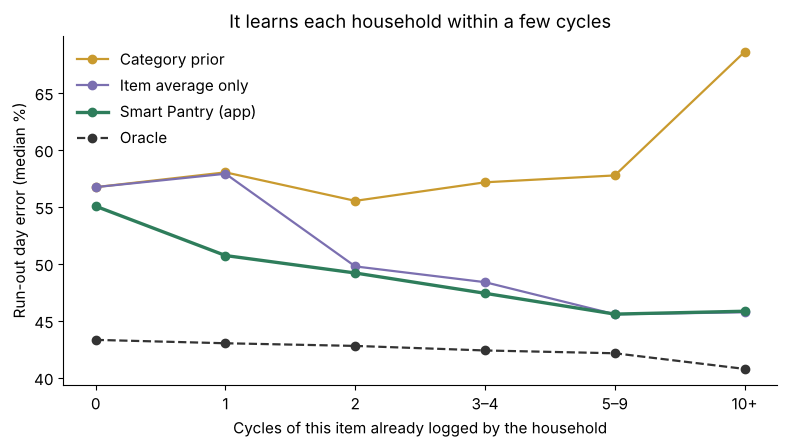

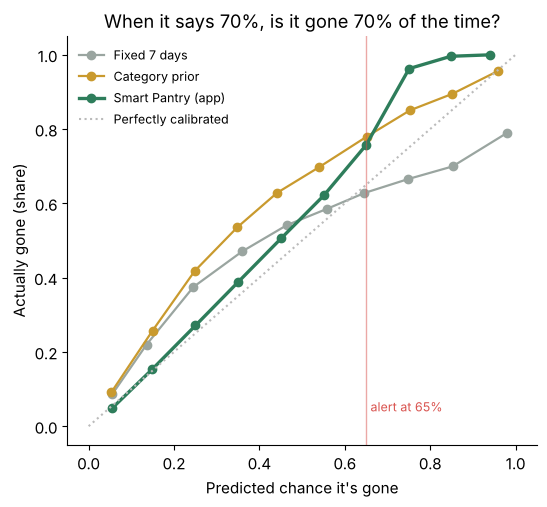

Saved figures and tables to /home/claude/ga_layout/notebooks/figures


In [8]:
COL = {"Fixed 7 days": "#9aa5a0", "Category prior": "#c99a2e", "Item average only": "#7b6fb0",
       "Smart Pantry (app)": "#2e7d5b", "Oracle": "#333333"}
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

# Learning curve
fig, ax = plt.subplots(figsize=(8, 4.6))
x = np.arange(len(curve))
for m in ["Category prior", "Item average only", "Smart Pantry (app)", "Oracle"]:
    ax.plot(x, curve[m], marker="o", lw=2.4 if m == "Smart Pantry (app)" else 1.6, color=COL[m], label=m,
            ls="--" if m == "Oracle" else "-")
ax.set_xticks(x, curve.index.astype(str))
ax.set_xlabel("Cycles of this item already logged by the household")
ax.set_ylabel("Run-out day error (median %)")
ax.set_title("It learns each household within a few cycles")
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG_DIR / "learning_curve.png", dpi=180)

# Calibration
fig, ax = plt.subplots(figsize=(5.6, 5.2))
bins = np.linspace(0, 1, 11)
for m in ["Fixed 7 days", "Category prior", "Smart Pantry (app)"]:
    p = days_df[m].values
    idx = np.minimum((p * 10).astype(int), 9)
    xs = [p[idx == b].mean() for b in range(10) if (idx == b).sum() > 200]
    ys = [y[idx == b].mean() for b in range(10) if (idx == b).sum() > 200]
    ax.plot(xs, ys, marker="o", color=COL[m], lw=2.4 if m == "Smart Pantry (app)" else 1.6, label=m)
ax.plot([0, 1], [0, 1], color="#bbb", ls=":", label="Perfectly calibrated")
ax.axvline(RESTOCK_THRESHOLD, color="#d9534f", lw=1, alpha=.5)
ax.text(RESTOCK_THRESHOLD + .01, .04, "alert at 65%", color="#d9534f", fontsize=9)
ax.set_xlabel("Predicted chance it's gone"); ax.set_ylabel("Actually gone (share)")
ax.set_title("When it says 70%, is it gone 70% of the time?")
ax.legend(frameon=False, fontsize=9, loc="upper left")
fig.tight_layout(); fig.savefig(FIG_DIR / "calibration.png", dpi=180)

if "ipykernel" in sys.modules:
    plt.show()
results.to_csv(FIG_DIR / "results.csv")
curve.to_csv(FIG_DIR / "learning_curve.csv")
still.to_csv(FIG_DIR / "still_have_it.csv")
print("Saved figures and tables to", FIG_DIR)